# Part 1: Reproducing the Paper

This notebook repeats the work in the paper **"CT based Patient Triage of COVID 19: Radiomics Prediction of ICU Admission, Mechanical Ventilation, and Death of Patients"** (Zhan and Li, Stanford CS229).

The goal is to predict three things for a COVID 19 patient when they come to hospital:
1. Will they need the ICU?
2. Will they need a ventilator?
3. Will they die?

The original paper used private hospital data, so we use the closest public dataset: the **Stony Brook University COVID 19 dataset** (TCIA). It has chest CT scans and patient records for the same three outcomes.

**What this notebook does, in short:**
1. Finds patients who have both a usable chest CT scan and clinical records (286 patients).
2. Turns each CT scan into numbers that describe the lungs (called radiomics features).
3. Joins these with clinical and blood test data, and splits the patients into train, validation and test groups.
4. Trains the same five models as the paper and picks the best one for each case.
5. Tests the chosen models, checks if the differences are real using statistics, and finds the most important features.

## Step 1: Install tools
Installs the tool used to search and download CT scans from the public imaging archive.

In [ ]:
!pip install -q idc-index pandas

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 77.3/77.3 MB 10.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.0/5.0 MB 68.9 MB/s eta 0:00:00


## Step 2: Load the clinical data
Loads the patient records file from TCIA and prints its size and column names. This shows us which columns hold the outcomes, the symptoms and the blood tests.

In [ ]:
import pandas as pd
clin = pd.read_csv('/content/deidentified_overlap_tcia.csv.cleaned.csv_20210806.csv')
print(clin.shape)
print(clin.columns.tolist())

(1384, 131)
['to_patient_id', 'covid19_statuses', 'last.status', 'age.splits', 'gender_concept_name', 'visit_start_datetime', 'visit_concept_name', 'is_icu', 'was_ventilated', 'invasive_vent_days', 'length_of_stay', 'Acute.Hepatic.Injury..during.hospitalization.', 'Acute.Kidney.Injury..during.hospitalization.', 'Urine.protein', 'kidney_replacement_therapy', 'kidney_transplant', 'htn_v', 'dm_v', 'cad_v', 'hf_ef_v', 'ckd_v', 'malignancies_v', 'copd_v', 'other_lung_disease_v', 'acei_v', 'arb_v', 'antibiotics_use_v', 'nsaid_use_v', 'days_prior_sx', 'smoking_status_v', 'cough_v', 'dyspnea_admission_v', 'nausea_v', 'vomiting_v', 'diarrhea_v', 'abdominal_pain_v', 'fever_v', 'BMI.over30', 'BMI.over35', 'temperature.over38', 'pulseOx.under90', 'Respiration.over24', 'HeartRate.over100', 'Lymphocytes.under1k', 'Aspartate.over40', 'Alanine.over60', 'A1C.over6.5', 'A1C.under6.5', 'A1C.6.6to7.9', 'A1C.8to9.9', 'A1C.over10', 'Sodium.above145', 'Sodium.between135and145', 'Sodium.below135', 'Potassium.

## Step 3: Count the CT scans
Searches the archive for all CT scans in this dataset. Nothing is downloaded yet. It only prints how many scans and patients there are, and the total size.

In [ ]:
from idc_index import IDCClient
c = IDCClient()
ct = c.index[(c.index.collection_id == 'covid_19_ny_sbu') & (c.index.Modality == 'CT')]
print('CT series:', len(ct), '| CT patients:', ct.PatientID.nunique())
print('Total size (GB):', round(ct.series_size_MB.sum() / 1024, 1))

CT series: 3730 | CT patients: 458
Total size (GB): 285.8


## Step 4: Check the outcomes
Keeps only patients who have both a CT scan and clinical records, then counts how many of them went to the ICU, needed a ventilator, or died.

In [ ]:
print(clin['last.status'].value_counts())
both = clin[clin.to_patient_id.isin(set(ct.PatientID))]
print('Patients with CT + clinical:', len(both))
for col in ['is_icu', 'was_ventilated', 'last.status']:
    print(both[col].value_counts(), '\n')

last.status
discharged    1201
deceased       183
Name: count, dtype: int64
Patients with CT + clinical: 458
is_icu
False    329
True     129
Name: count, dtype: int64 

was_ventilated
No     356
Yes    102
Name: count, dtype: int64 

last.status
discharged    375
deceased       83
Name: count, dtype: int64 



## Step 5: Look at the scan types
Checks which body parts the scans cover. Many scans are not labelled, so this tells us we need another way to find the chest scans.

In [ ]:
print(ct.BodyPartExamined.value_counts().head(15))
chest = ct[ct.BodyPartExamined.str.upper().str.contains('CHEST', na=False)]
print('Chest CT patients:', chest.PatientID.nunique(), '| GB:', round(chest.series_size_MB.sum() / 1024, 1))
print(chest[['SeriesDescription', 'instanceCount', 'series_size_MB']].sample(20, random_state=0))

BodyPartExamined
CHEST             468
CHESTABDPELVIS    207
ABDOMEN           150
ABDOMENPELVIS      20
Name: count, dtype: int64
Chest CT patients: 111 | GB: 57.6
       SeriesDescription  instanceCount  series_size_MB
117283        Body 3.000            126       66.556888
103656     Body 3.000 CE             97       51.251162
112352          Lung 5.0             73       38.561042
106784      CTA 3.000 CE            132       69.742646
113374          Lung 5.0             59       31.166356
111025     Body 3.000 CE            110       58.121014
111636          Lung 5.0             64       33.806242
103404          Lung 1.0            236      124.669906
109416        Body 3.000            101       53.352906
106435        CTA 1.0 CE            301      159.033554
116451        Body 3.000             87       45.956386
117048        CTA 1.0 CE            323      170.654068
106879     Body 3.000 CE            140      155.561214
120596     Body 3.000 CE             85       49.19

## Step 6: Find thin lung scans
Uses the scan description to find scans made with a lung setting and thin slices (2.5 mm or less), like the paper did. Very short scans are removed. This leaves 286 patients.

In [ ]:
ct = ct.copy()
ct['desc'] = ct.SeriesDescription.fillna('').str.lower()
ct['thick'] = ct.desc.str.extract(r'(\d+\.?\d*)')[0].astype(float)
ct['is_lung'] = ct.desc.str.contains('lung')
print(ct.desc.value_counts().head(30))
lung_thin = ct[ct.is_lung & (ct.thick <= 2.5) & (ct.instanceCount >= 100)]
print('Thin lung-kernel patients:', lung_thin.PatientID.nunique(), '| GB:', round(lung_thin.series_size_MB.sum() / 1024, 1))
print('Any lung-kernel patients:', ct[ct.is_lung].PatientID.nunique())
sel = both[both.to_patient_id.isin(lung_thin.PatientID)]
for col in ['is_icu', 'was_ventilated', 'last.status']: print(sel[col].value_counts().to_dict())

desc
scout ap/lat         275
lung 5 mm            257
chest sagittal       210
body 3.000 ce        178
chest coronal        166
2.0                  137
lung hr 1.25 mm      135
5 mm standard        135
scout ap/lateral     135
abd coronal          133
coronal pe mip       123
lung 1.25 mm         122
1 25 mm coronal      117
1 25 mm sagital      117
chest 1.25 mm        116
body 3.000           108
abd sag               89
abd/pel 2.5 mm        56
cta 3.000 ce          53
lung 1.0              46
body 5.0              46
lung 5.0              46
smart prep series     45
standard 2.5mm        44
body 1.0 ce           43
body 3.0 ce           41
rfmt                  40
cta 15.000 ce         39
ref                   34
                      33
Name: count, dtype: int64
Thin lung-kernel patients: 286 | GB: 43.2
Any lung-kernel patients: 306
{False: 202, True: 84}
{'No': 213, 'Yes': 73}
{'discharged': 235, 'deceased': 51}


## Step 7: Pick one scan per patient
For each patient, keeps the earliest scan (closest to when they came to hospital), and if there is a tie, the thinnest one. The list is saved to `selected_series.csv`.

In [ ]:
pick = (lung_thin.sort_values(['PatientID', 'StudyDate', 'thick', 'instanceCount'],
                              ascending=[True, True, True, False])
                 .drop_duplicates('PatientID'))
pick[['PatientID', 'SeriesInstanceUID', 'StudyDate', 'desc']].to_csv('/content/selected_series.csv', index=False)
print(len(pick))

286


## Step 8: Install the imaging tools
Installs the tools for reading CT scans, finding the lungs in a scan (lungmask), and measuring the lungs (PyRadiomics).

In [ ]:
!pip install -q idc-index lungmask git+https://github.com/AIM-Harvard/pyradiomics.git

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.2/79.2 MB 11.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.0/5.0 MB 84.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.7/13.7 MB 105.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.8/52.8 MB 17.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 73.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 93.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 118.1/118.1 kB 12.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.4/7.4 MB 90.2 MB/s eta 0:00:00


## Step 9: Set up the feature extraction
Creates a function that, for one patient, downloads the scan, finds the lungs, measures 107 features of the lungs (shape, brightness and texture), and then deletes the scan to save space.

In [ ]:
import os, glob, shutil, logging
import numpy as np, pandas as pd, SimpleITK as sitk
from idc_index import IDCClient
from lungmask import LMInferer
from radiomics import featureextractor, logger
logger.setLevel(logging.ERROR)

client = IDCClient()
inferer = LMInferer()
ext = featureextractor.RadiomicsFeatureExtractor(binWidth=25, resampledPixelSpacing=[2, 2, 2], preCrop=True)
ext.enableImageTypes(Original={})

def extract_one(pid, uid, tmp='/content/tmp'):
    shutil.rmtree(tmp, ignore_errors=True)
    client.download_from_selection(seriesInstanceUID=[uid], downloadDir=tmp)
    folder = os.path.dirname(glob.glob(f'{tmp}/**/*.dcm', recursive=True)[0])
    reader = sitk.ImageSeriesReader()
    reader.SetFileNames(reader.GetGDCMSeriesFileNames(folder))
    img = reader.Execute()
    mask = sitk.GetImageFromArray((inferer.apply(img) > 0).astype(np.uint8))
    mask.CopyInformation(img)
    feats = ext.execute(img, mask)
    shutil.rmtree(tmp, ignore_errors=True)
    row = {'patient_id': pid}
    row.update({k: float(v) for k, v in feats.items() if not k.startswith('diagnostics')})
    return row

Downloading: "https://github.com/JoHof/lungmask/releases/download/v0.0/unet_r231-d5d2fc3d.pth" to /root/.cache/torch/hub/checkpoints/unet_r231-d5d2fc3d.pth


100%|██████████| 119M/119M [00:00<00:00, 248MB/s] 


## Step 10: Run the extraction for all patients
Runs the function from the last step for every patient and saves the results after each one. If the session stops, running this cell again continues from where it stopped.

Note: an earlier run saved some patients in `radiomics_part0.csv`. Those patients are skipped, and only their original features are used later.

In [ ]:
sel = pd.read_csv('/content/selected_series.csv')
old = '/content/radiomics_part0.csv'
out = '/content/radiomics_orig.csv'
done = set()
for f in [old, out]:
    if os.path.exists(f): done |= set(pd.read_csv(f).patient_id)
todo = sel[~sel.PatientID.isin(done)]
print(f'{len(done)} done, {len(todo)} to go')
for i, r in enumerate(todo.itertuples(), 1):
    try:
        row = extract_one(r.PatientID, r.SeriesInstanceUID)
        pd.DataFrame([row]).to_csv(out, mode='a', header=not os.path.exists(out), index=False)
        print(i, r.PatientID, 'ok')
    except Exception as e:
        print(i, r.PatientID, 'FAILED:', e)
        with open('/content/failed.txt', 'a') as f: f.write(f'{r.PatientID}\t{e}\n')

122 done, 164 to go


 95%|█████████▍| 11/11.6 [00:07<00:00,  2.26it/s]/usr/local/lib/python3.13/dist-packages/tqdm/std.py:636: TqdmWarning: clamping frac to range [0, 1]
  full_bar = Bar(frac,
103%|██████████| 12/11.6 [00:07<-00:00,  1.62it/s]

lungmask 2026-10-09 12:53:57 Postprocessing



100%|██████████| 7/7 [00:00<00:00, 105.31it/s]


1 A464604 ok


15it [00:06,  2.39it/s]

... (647 outputs left out)

18it [00:09,  1.86it/s]

lungmask 2026-10-09 15:03:48 Postprocessing



100%|██████████| 2/2 [00:00<00:00, 242.34it/s]


164 A994393 ok


## Step 11: Build the final table and split the patients
Joins the CT features with the clinical and blood test data. Columns that describe things that happened later in the hospital stay are left out, so the models only use information available on arrival. Columns missing for more than half the patients are removed.

Then the patients are split once into **train (140)**, **validation (60)** and **test (86)**, keeping the same share of deaths in each group. The files `features.csv` and `split.csv` are saved and reused by both parts of the project.

In [ ]:
import re, numpy as np, pandas as pd
from sklearn.model_selection import train_test_split

D = '/content/'
clin = pd.read_csv(D + 'clinical.csv')

# radiomics: combine both runs, keep only original-image features
orig = pd.read_csv(D + 'radiomics_orig.csv')
part0 = pd.read_csv(D + 'radiomics_part0.csv')[orig.columns]
rad = pd.concat([part0, orig], ignore_index=True)
rad.columns = ['patient_id'] + ['rad_' + c for c in rad.columns[1:]]

# labels
yes = lambda s: s.astype(str).str.strip().str.lower().isin(['true', 'yes', '1', '1.0'])
lab_df = pd.DataFrame({'patient_id': clin.to_patient_id,
                       'icu': yes(clin.is_icu).astype(int),
                       'mv': yes(clin.was_ventilated).astype(int),
                       'death': (clin['last.status'].str.lower() == 'deceased').astype(int)})

# clinical features: demographics, comorbidities, symptoms, vitals (admission only)
def to_num(s):
    m = s.astype(str).str.strip().str.lower().map({'yes': 1, 'true': 1, 'no': 0, 'false': 0})
    return m.where(s.notna(), np.nan) if m.notna().any() else pd.to_numeric(s, errors='coerce')

c = pd.DataFrame({'patient_id': clin.to_patient_id})
c['age'] = pd.to_numeric(clin['age.splits'].astype(str).str.extract(r'(\d+)')[0], errors='coerce')
c['male'] = (clin.gender_concept_name.str.upper() == 'MALE').astype(int)
binary_cols = ['htn_v', 'dm_v', 'cad_v', 'hf_ef_v', 'ckd_v', 'malignancies_v', 'copd_v',
               'other_lung_disease_v', 'acei_v', 'arb_v', 'nsaid_use_v',
               'cough_v', 'dyspnea_admission_v', 'nausea_v', 'vomiting_v',
               'diarrhea_v', 'abdominal_pain_v', 'fever_v']
for col in binary_cols:
    c[col] = to_num(clin[col])
c['days_prior_sx'] = pd.to_numeric(clin.days_prior_sx, errors='coerce')
c = c.join(pd.get_dummies(clin.smoking_status_v, prefix='smoking', dtype=int))
vital_codes = ['8331-1', '59408-5', '9279-1', '76282-3', '8480-6', '76536-2', '39156-5']
for col in clin.columns:
    if col.split('_')[0] in vital_codes:
        c[col] = pd.to_numeric(clin[col], errors='coerce')
c.columns = ['patient_id'] + ['clin_' + x for x in c.columns[1:]]

# lab features: raw numeric lab values (LOINC columns), excluding vitals/duplicates
l = pd.DataFrame({'patient_id': clin.to_patient_id})
for col in clin.columns:
    if re.match(r'^\d+-\d_', col) and col.split('_')[0] not in vital_codes and not col.endswith('.1'):
        l['lab_' + col] = pd.to_numeric(clin[col], errors='coerce')

# merge (only the 286 CT patients)
df = rad.merge(lab_df, on='patient_id').merge(c, on='patient_id').merge(l, on='patient_id')

# drop clinical/lab columns missing in >50% of patients or constant
cl = [x for x in df.columns if x.startswith(('clin_', 'lab_'))]
drop = [x for x in cl if df[x].isna().mean() > 0.5 or df[x].nunique() <= 1]
df = df.drop(columns=drop)
df.to_csv(D + 'features.csv', index=False)

print('Patients:', len(df))
print('Radiomics:', sum(x.startswith('rad_') for x in df.columns),
      '| Clinical:', sum(x.startswith('clin_') for x in df.columns),
      '| Lab:', sum(x.startswith('lab_') for x in df.columns))
print('Dropped (too missing/constant):', len(drop))
print('Positives:', df[['icu', 'mv', 'death']].sum().to_dict())

# Step 6: split once, stratified on death
dev, test = train_test_split(df.patient_id, test_size=0.30, stratify=df.death, random_state=42)
tr, val = train_test_split(dev, test_size=0.30, stratify=df.set_index('patient_id').loc[dev, 'death'], random_state=42)
split = pd.concat([pd.DataFrame({'patient_id': tr, 'split': 'train'}),
                   pd.DataFrame({'patient_id': val, 'split': 'val'}),
                   pd.DataFrame({'patient_id': test, 'split': 'test'})])
split.to_csv(D + 'split.csv', index=False)
summary = split.merge(df[['patient_id', 'icu', 'mv', 'death']]).groupby('split')
print(summary.size().rename('patients').to_frame().join(summary[['icu', 'mv', 'death']].sum()))

Patients: 286
Radiomics: 107 | Clinical: 30 | Lab: 21
Dropped (too missing/constant): 8
Positives: {'icu': 84, 'mv': 73, 'death': 51}
       patients  icu  mv  death
split                          
test         86   25  21     15
train       140   39  35     25
val          60   20  17     11


## Step 12: Install the model tools
Installs the extra tools needed for balancing the data (SMOTEENN) and for the LightGBM model.

In [ ]:
!pip install -q imbalanced-learn lightgbm

## Step 13: Train and compare the models
For each outcome and each feature group, this tries every mix of:
* **4 feature groups:** CT only (Radiom), CT + clinical (RadioClin), CT + clinical + blood tests (RadioClinLab), clinical + blood tests (ClinLab)
* **4 ways to prepare the data:** as is, balanced with SMOTEENN, balanced then LASSO feature selection, balanced then PCA
* **5 models:** Logistic Regression, Random Forest, SVM, MLP and LightGBM

Each mix is tuned with 5 fold cross validation on the train group. The best one for each outcome and feature group is chosen by its score on the validation group. This gives our version of the paper's Table 1.

In [ ]:
import warnings, time, joblib, numpy as np, pandas as pd
warnings.filterwarnings('ignore')
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.feature_selection import SelectFromModel
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import roc_auc_score, accuracy_score, average_precision_score
from imblearn.pipeline import Pipeline
from imblearn.combine import SMOTEENN
from lightgbm import LGBMClassifier

D = '/content/'
SEED = 42
df = pd.read_csv(D + 'features.csv').merge(pd.read_csv(D + 'split.csv'), on='patient_id')
train, val = df[df.split == 'train'], df[df.split == 'val']

cols = lambda *p: [c for c in df.columns if c.startswith(p)]
FEATURE_SETS = {'Radiom': cols('rad_'),
                'RadioClin': cols('rad_', 'clin_'),
                'RadioClinLab': cols('rad_', 'clin_', 'lab_'),
                'ClinLab': cols('clin_', 'lab_')}

lasso = SelectFromModel(LogisticRegression(penalty='l1', solver='liblinear', random_state=SEED))
PREPROC = {  # name -> (steps, extra grid)
    'Raw':            ([], {}),
    'SMOTEENN':       ([('res', SMOTEENN(random_state=SEED))], {}),
    'SMOTEENN+LASSO': ([('res', SMOTEENN(random_state=SEED)), ('sel', lasso)],
                       {'sel__estimator__C': [0.5, 1, 50]}),
    'SMOTEENN+PCA':   ([('res', SMOTEENN(random_state=SEED)), ('sel', PCA(n_components=0.95, random_state=SEED))], {}),
}
MODELS = {  # name -> (estimator, grid)
    'LR':       (LogisticRegression(max_iter=5000, random_state=SEED), {'clf__C': [0.1, 1]}),
    'RF':       (RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=1), {'clf__max_depth': [3, None]}),
    'SVM':      (SVC(probability=True, random_state=SEED), {'clf__C': [0.1, 1]}),
    'MLP':      (MLPClassifier(hidden_layer_sizes=(32,), max_iter=2000, random_state=SEED), {'clf__alpha': [1e-3, 1e-1]}),
    'LightGBM': (LGBMClassifier(n_estimators=100, learning_rate=0.05, min_child_samples=5,
                                random_state=SEED, verbose=-1, n_jobs=1), {'clf__num_leaves': [7, 15]}),
}
cv = StratifiedKFold(5, shuffle=True, random_state=SEED)

rows, best = [], {}
t0 = time.time()
for task in ['icu', 'mv', 'death']:
    for fs, fcols in FEATURE_SETS.items():
        for pn, (psteps, pgrid) in PREPROC.items():
            for mn, (est, mgrid) in MODELS.items():
                pipe = Pipeline([('imp', SimpleImputer(strategy='median')), ('sc', StandardScaler()),
                                 *psteps, ('clf', est)])
                gs = GridSearchCV(pipe, {**pgrid, **mgrid}, scoring='roc_auc', cv=cv, n_jobs=-1)
                gs.fit(train[fcols], train[task])
                p = gs.predict_proba(val[fcols])[:, 1]
                rows.append({'task': task, 'data': fs, 'preproc': pn, 'model': mn,
                             'cv_auroc': gs.best_score_,
                             'AUROC': roc_auc_score(val[task], p),
                             'ACC': accuracy_score(val[task], p >= 0.5),
                             'AUPRC': average_precision_score(val[task], p),
                             'params': gs.best_params_})
                key = (task, fs)
                if key not in best or rows[-1]['AUROC'] > best[key]['AUROC']:
                    best[key] = {**rows[-1], 'estimator': gs.best_estimator_}
        print(f'{task} / {fs} done ({time.time() - t0:.0f}s)')

allres = pd.DataFrame(rows)
allres.to_csv(D + 'all_results.csv', index=False)
joblib.dump(best, D + 'best_models.pkl')

table1 = pd.DataFrame([{k: v for k, v in b.items() if k != 'estimator'} for b in best.values()])
table1.to_csv(D + 'table1_val.csv', index=False)
pd.set_option('display.width', 200)
print(table1.pivot(index='data', columns='task', values=['AUROC', 'ACC', 'AUPRC'])
      .reindex(FEATURE_SETS).round(3))
print(table1[['task', 'data', 'preproc', 'model', 'params']].to_string(index=False))

icu / Radiom done (68s)
icu / RadioClin done (108s)
icu / RadioClinLab done (149s)
icu / ClinLab done (186s)
mv / Radiom done (232s)
mv / RadioClin done (272s)
mv / RadioClinLab done (312s)
mv / ClinLab done (349s)
death / Radiom done (394s)
death / RadioClin done (435s)
death / RadioClinLab done (475s)
death / ClinLab done (512s)
              AUROC                  ACC                AUPRC              
task          death    icu     mv  death    icu     mv  death    icu     mv
data                                                                       
Radiom        0.722  0.594  0.689  0.850  0.550  0.717  0.497  0.407  0.590
RadioClin     0.751  0.592  0.732  0.550  0.667  0.750  0.561  0.405  0.634
RadioClinLab  0.848  0.644  0.726  0.583  0.433  0.717  0.667  0.482  0.538
ClinLab       0.840  0.704  0.665  0.800  0.683  0.683  0.525  0.584  0.437
 task         data        preproc    model                                         params
  icu       Radiom SMOTEENN+LASSO LightGBM {'

## Step 14: Test the chosen models
Retrains each chosen model on the train and validation groups together, then tests it once on the test group. It draws the ROC and precision recall curves (like the paper's Fig. 2).

Then it repeats the test 30 times on random resamples of the test group (bootstrapping) and uses paired t tests to check if adding clinical data really helps. The box plots match the paper's Fig. 3. The resamples are saved so Part 2 can use the exact same ones.

              AUROC                AUPRC              
task            icu     mv  death    icu     mv  death
data                                                  
Radiom        0.631  0.730  0.623  0.424  0.660  0.353
RadioClin     0.645  0.649  0.766  0.442  0.459  0.387
RadioClinLab  0.676  0.760  0.800  0.579  0.661  0.426
ClinLab       0.842  0.688  0.774  0.706  0.448  0.362


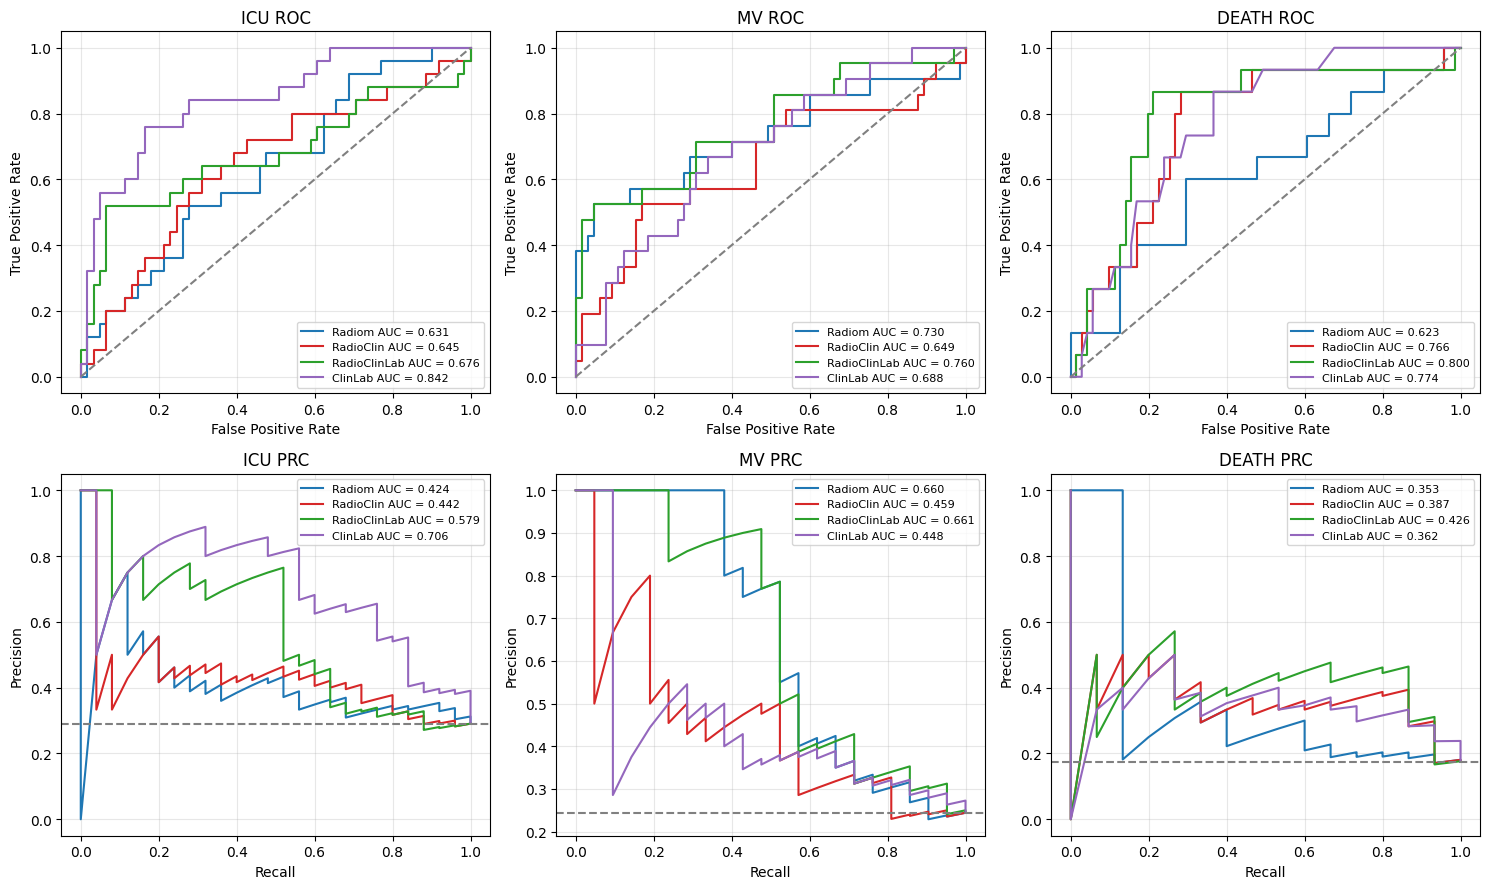

 task metric             comparison  mean_diff  p_value
  icu  AUROC     RadioClin > Radiom     0.0328   0.0010
  icu  AUROC RadioClinLab > ClinLab    -0.1939   1.0000
  icu  AUROC  RadioClinLab > Radiom     0.0391   0.0002
  icu  AUPRC     RadioClin > Radiom     0.0339   0.0041
  icu  AUPRC RadioClinLab > ClinLab    -0.1548   1.0000
  icu  AUPRC  RadioClinLab > Radiom     0.1403   0.0000
   mv  AUROC     RadioClin > Radiom    -0.1117   1.0000
   mv  AUROC RadioClinLab > ClinLab     0.0846   0.0000
   mv  AUROC  RadioClinLab > Radiom     0.0198   0.0438
   mv  AUPRC     RadioClin > Radiom    -0.2105   1.0000
   mv  AUPRC RadioClinLab > ClinLab     0.2010   0.0000
   mv  AUPRC  RadioClinLab > Radiom    -0.0208   0.9209
death  AUROC     RadioClin > Radiom     0.1502   0.0000
death  AUROC RadioClinLab > ClinLab     0.0124   0.1341
death  AUROC  RadioClinLab > Radiom     0.1874   0.0000
death  AUPRC     RadioClin > Radiom     0.0655   0.0005
death  AUPRC RadioClinLab > ClinLab     0.0544  

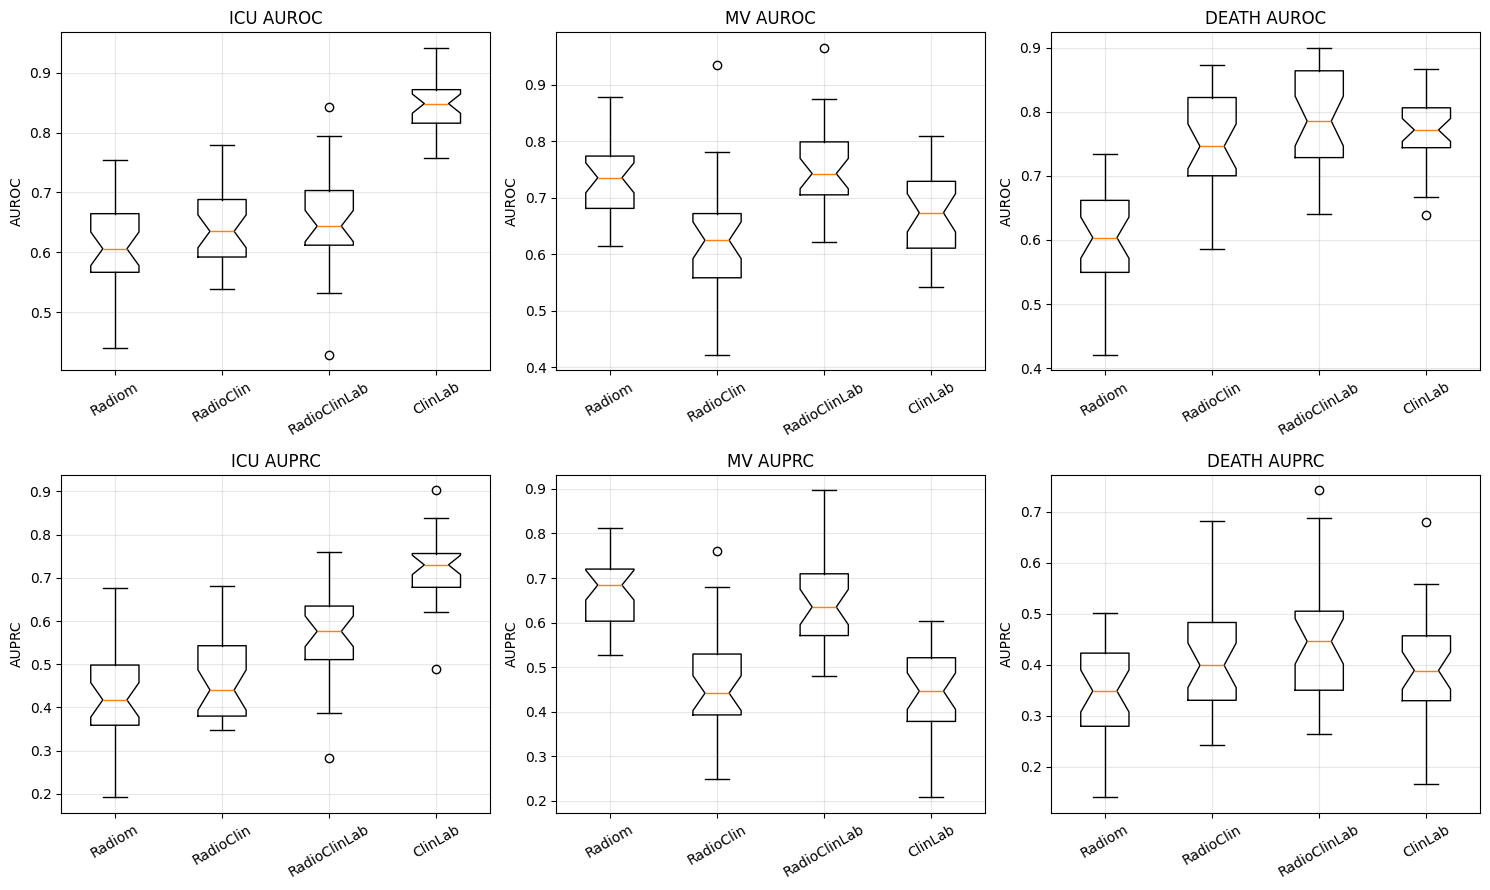

In [ ]:
import warnings, joblib, numpy as np, pandas as pd, matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
from sklearn.base import clone
from sklearn.metrics import roc_auc_score, accuracy_score, average_precision_score, roc_curve, precision_recall_curve
from scipy.stats import ttest_rel

D = '/content/'
SEED = 42
TASKS = ['icu', 'mv', 'death']
DATAS = ['Radiom', 'RadioClin', 'RadioClinLab', 'ClinLab']
COLORS = {'Radiom': 'tab:blue', 'RadioClin': 'tab:red', 'RadioClinLab': 'tab:green', 'ClinLab': 'tab:purple'}

df = pd.read_csv(D + 'features.csv').merge(pd.read_csv(D + 'split.csv'), on='patient_id')
dev, test = df[df.split != 'test'], df[df.split == 'test'].reset_index(drop=True)
cols = lambda *p: [c for c in df.columns if c.startswith(p)]
FEATURE_SETS = {'Radiom': cols('rad_'), 'RadioClin': cols('rad_', 'clin_'),
                'RadioClinLab': cols('rad_', 'clin_', 'lab_'), 'ClinLab': cols('clin_', 'lab_')}
best = joblib.load(D + 'best_models.pkl')

# Step 8: retrain each chosen model on train+val, predict the test set
preds, final, rows = {'patient_id': test.patient_id}, {}, []
for task in TASKS:
    for d in DATAS:
        m = clone(best[(task, d)]['estimator']).fit(dev[FEATURE_SETS[d]], dev[task])
        final[(task, d)] = m
        p = m.predict_proba(test[FEATURE_SETS[d]])[:, 1]
        preds[f'{task}_{d}'] = p
        rows.append({'task': task, 'data': d, 'model': f"{best[(task, d)]['preproc']} + {best[(task, d)]['model']}",
                     'AUROC': roc_auc_score(test[task], p), 'ACC': accuracy_score(test[task], p >= 0.5),
                     'AUPRC': average_precision_score(test[task], p)})
preds = pd.DataFrame(preds)
preds.to_csv(D + 'test_predictions.csv', index=False)
joblib.dump(final, D + 'final_models.pkl')
test_res = pd.DataFrame(rows)
test_res.to_csv(D + 'test_results.csv', index=False)
print(test_res.pivot(index='data', columns='task', values=['AUROC', 'AUPRC']).reindex(DATAS)[
      [('AUROC', t) for t in TASKS] + [('AUPRC', t) for t in TASKS]].round(3))

# Fig. 2: ROC (top) and PR (bottom) curves on the test set
fig, ax = plt.subplots(2, 3, figsize=(15, 9))
for j, task in enumerate(TASKS):
    y = test[task]
    for d in DATAS:
        p = preds[f'{task}_{d}']
        fpr, tpr, _ = roc_curve(y, p)
        ax[0, j].plot(fpr, tpr, color=COLORS[d], label=f'{d} AUC = {roc_auc_score(y, p):.3f}')
        pr, rc, _ = precision_recall_curve(y, p)
        ax[1, j].plot(rc, pr, color=COLORS[d], label=f'{d} AUC = {average_precision_score(y, p):.3f}')
    ax[0, j].plot([0, 1], [0, 1], '--', color='grey')
    ax[0, j].set(title=f'{task.upper()} ROC', xlabel='False Positive Rate', ylabel='True Positive Rate')
    ax[1, j].axhline(y.mean(), ls='--', color='grey')
    ax[1, j].set(title=f'{task.upper()} PRC', xlabel='Recall', ylabel='Precision')
    for a in ax[:, j]: a.legend(loc='lower right' if a in ax[0] else 'upper right', fontsize=8); a.grid(alpha=.3)
plt.tight_layout(); plt.savefig(D + 'fig2_roc_prc.png', dpi=150); plt.show()

# Step 9: 30 bootstraps of the test set + paired one-sided t-tests
rng = np.random.default_rng(SEED)
boot_idx = []
while len(boot_idx) < 30:
    idx = rng.integers(0, len(test), len(test))
    if all(test.loc[idx, t].nunique() == 2 for t in TASKS):   # both classes present for every task
        boot_idx.append(idx)
np.save(D + 'boot_idx.npy', np.array(boot_idx))

boot = []
for b, idx in enumerate(boot_idx):
    for task in TASKS:
        y = test.loc[idx, task].values
        for d in DATAS:
            p = preds.loc[idx, f'{task}_{d}'].values
            boot.append({'boot': b, 'task': task, 'data': d,
                         'AUROC': roc_auc_score(y, p), 'AUPRC': average_precision_score(y, p)})
boot = pd.DataFrame(boot)
boot.to_csv(D + 'bootstrap_results.csv', index=False)

COMPARE = [('RadioClin', 'Radiom'), ('RadioClinLab', 'ClinLab'), ('RadioClinLab', 'Radiom')]
tt = []
for task in TASKS:
    for metric in ['AUROC', 'AUPRC']:
        w = boot[boot.task == task].pivot(index='boot', columns='data', values=metric)
        for a, b in COMPARE:
            tt.append({'task': task, 'metric': metric, 'comparison': f'{a} > {b}',
                       'mean_diff': (w[a] - w[b]).mean(),
                       'p_value': ttest_rel(w[a], w[b], alternative='greater').pvalue})
tt = pd.DataFrame(tt)
tt.to_csv(D + 'ttests.csv', index=False)
print(tt.round(4).to_string(index=False))

# Fig. 3: box plots of bootstrapped AUROC / AUPRC
fig, ax = plt.subplots(2, 3, figsize=(15, 9))
for i, metric in enumerate(['AUROC', 'AUPRC']):
    for j, task in enumerate(TASKS):
        s = boot[boot.task == task]
        ax[i, j].boxplot([s[s.data == d][metric] for d in DATAS], notch=True)
        ax[i, j].set_xticks(range(1, 5), DATAS, rotation=30)
        ax[i, j].set(title=f'{task.upper()} {metric}', ylabel=metric); ax[i, j].grid(alpha=.3)
plt.tight_layout(); plt.savefig(D + 'fig3_bootstrap.png', dpi=150); plt.show()

## Step 15: Find the most important features
For the models that use all the data (RadioClinLab), this measures how much the score drops when each feature is shuffled. The bigger the drop, the more important the feature. It lists the top 10 features for each outcome, like the paper's Table S1.

In [ ]:
import re
from sklearn.inspection import permutation_importance

# Step 10: top-10 features of the RadioClinLab models (permutation importance on the test set)
fcols = FEATURE_SETS['RadioClinLab']
top = {}
for task in TASKS:
    r = permutation_importance(final[(task, 'RadioClinLab')], test[fcols], test[task],
                               scoring='roc_auc', n_repeats=30, random_state=SEED, n_jobs=-1)
    imp = pd.Series(r.importances_mean, index=fcols)
    imp = (imp.clip(lower=0) / imp.clip(lower=0).sum()).sort_values(ascending=False)  # normalised
    top[task] = [f"{re.sub(r'^\d+-\d_', '', c.split('_', 1)[1]).split(' [')[0][:40]} ({c.split('_')[0]})"
                 for c in imp.index[:10]]
tableS1 = pd.DataFrame(top, index=range(1, 11))
tableS1.to_csv(D + 'tableS1_top_features.csv')
print(tableS1.to_string())

                                                icu                                               mv                                            death
1   Oxygen saturation in Arterial blood by P (clin)                                    Lactate (lab)                                    Lactate (lab)
2                                     Lactate (lab)                                    Glucose (lab)  Oxygen saturation in Arterial blood by P (clin)
3                                 Bicarbonate (lab)  Oxygen saturation in Arterial blood by P (clin)                                       age (clin)
4                           Respiratory rate (clin)                                    acei_v (clin)                            malignancies_v (clin)
5                                      Sodium (lab)                     Body mass index (BMI) (clin)             Erythrocyte sedimentation rate (lab)
6                              smoking_Never (clin)                  original_ngtdm_Complexity (rad)